In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply standard style across all plots
set_style()

# Exponential Distribution: Modeling Continuous Waiting Times & Survival

## 1. Intuition & Motivation

In the Poisson distribution, we asked: *"How many events occur in a fixed hour?"*
In the Exponential distribution, we invert the question to continuous time:
***"How long do I have to wait until the next event occurs?"***

- How many minutes until the next emergency room patient arrives?
- How many hours will a lightbulb or hard drive operate before burning out?
- How many seconds until the next radioactive particle decays?
- How long until a customer completes a checkout transaction?

The **Exponential distribution** models the time between independent events that occur continuously at a constant average rate $\lambda$. It is the cornerstone of **survival analysis**, **reliability engineering**, and **queuing theory**.

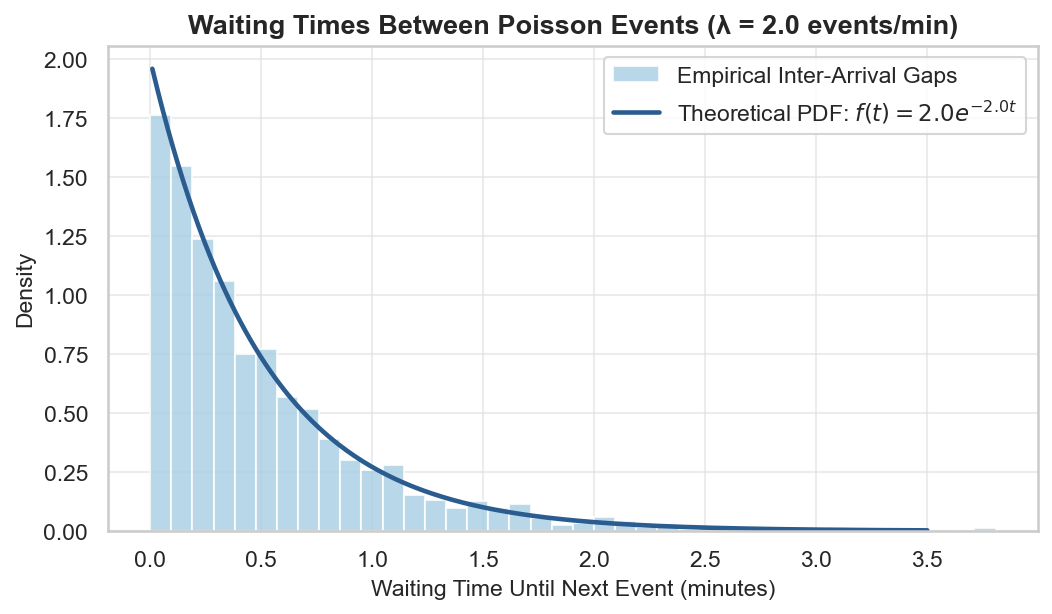

Sample Mean Waiting Time: 0.507 mins (Theoretical: 0.500 mins)
Sample Std Deviation:     0.513 mins (Theoretical: 0.500 mins)


In [2]:
# Arrival rate: lambda = 2.0 events per minute
lam_rate = 2.0
n_events = 2000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# In a Poisson process, inter-arrival gaps follow Exponential(scale = 1/lambda)
waiting_times = rng.exponential(scale=1.0 / lam_rate, size=n_events)

# Plot empirical waiting times
plt.figure(figsize=(8, 4.2))
plt.hist(
    waiting_times,
    bins=40,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label="Empirical Inter-Arrival Gaps",
)

# Theoretical Exponential curve
t_eval = np.linspace(0.01, 3.5, 300)
plt.plot(
    t_eval,
    stats.expon.pdf(t_eval, scale=1.0 / lam_rate),
    color=PALETTE["primary"],
    linewidth=2.2,
    label=f"Theoretical PDF: $f(t) = {lam_rate} e^{{-{lam_rate}t}}$",
)

plt.title(
    f"Waiting Times Between Poisson Events (λ = {lam_rate} events/min)",
    weight="bold",
)
plt.xlabel("Waiting Time Until Next Event (minutes)")
plt.ylabel("Density")
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean Waiting Time: {np.mean(waiting_times):.3f} mins (Theoretical: {1/lam_rate:.3f} mins)")
print(f"Sample Std Deviation:     {np.std(waiting_times, ddof=1):.3f} mins (Theoretical: {1/lam_rate:.3f} mins)")

## 2. Mathematical Definition

A continuous random variable $X$ follows an Exponential distribution with rate $\lambda$, written:
$$X \sim \text{Exponential}(\lambda)$$

### Parameters & Support
- **Rate $\lambda > 0$**: Frequency of events per unit time (arrivals per minute).
- **Scale $\beta = \frac{1}{\lambda}$**: Mean waiting time between events (minutes per arrival).
- **Support**: Non-negative real numbers: $x \in [0, \infty)$.

### Probability Density Function (PDF)
$$f(x) = \lambda e^{-\lambda x} \quad \text{for } x \ge 0$$

### Cumulative Distribution Function (CDF) & Survival Function
$$F(x) = P(X \le x) = 1 - e^{-\lambda x}$$
The **Survival Function** (probability of surviving beyond time $x$) is exceptionally clean:
$$S(x) = P(X > x) = e^{-\lambda x}$$

### Hazard Rate (Failure Rate)
The instantaneous risk of failure given survival up to time $x$ is **constant**:
$$h(x) = \frac{f(x)}{S(x)} = \frac{\lambda e^{-\lambda x}}{e^{-\lambda x}} = \lambda$$

### SciPy Parameterization Convention
SciPy uses the **scale parameter $\beta = \frac{1}{\lambda}$**:
`scipy.stats.expon(scale=1/lambda)`
*(e.g., if $\lambda = 2.0$, use `scale = 0.5`).*

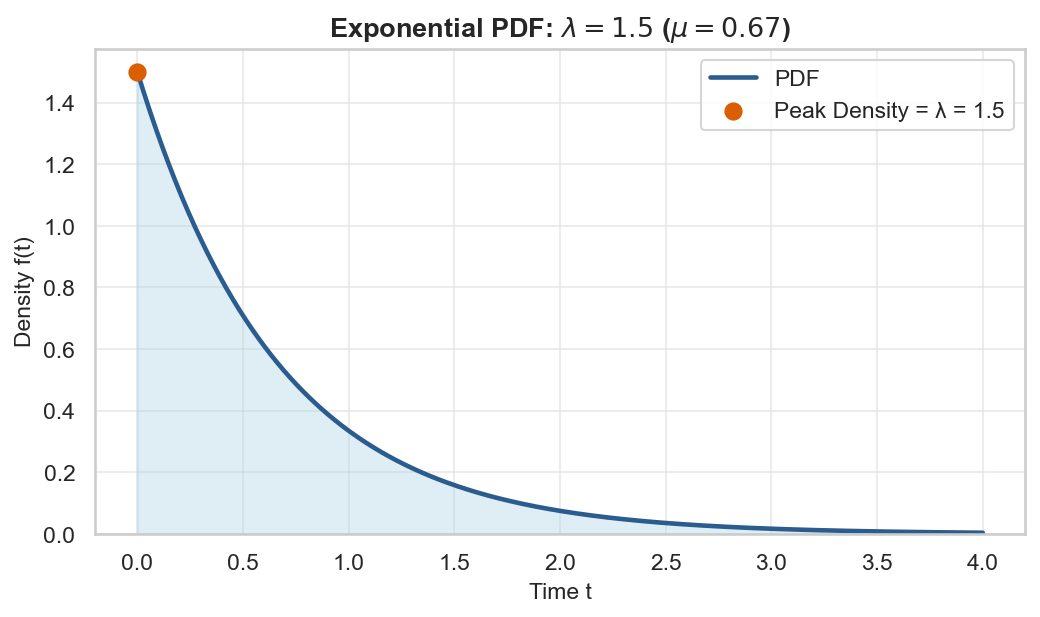

In [4]:
# Parameters
lam = 1.5
scale = 1.0 / lam

t_axis = np.linspace(0.0, 4.0, 400)
pdf_vals = stats.expon.pdf(t_axis, scale=scale)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    t_axis,
    pdf_vals,
    title=rf"Exponential PDF: $\lambda = {lam}$ ($\mu = {scale:.2f}$)",
    xlabel="Time t",
    ylabel="Density f(t)",
    fill=True,
    ax=ax,
)
ax.scatter([0], [lam], color=PALETTE["secondary"], s=60, zorder=5, label=f"Peak Density = λ = {lam}")
ax.legend(frameon=True)
plt.show()

<>:20: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:20: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\Shashank\AppData\Local\Temp\ipykernel_33448\3277170134.py:20: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  label="Survival Function S(t) = $e^{-\lambda t}$",


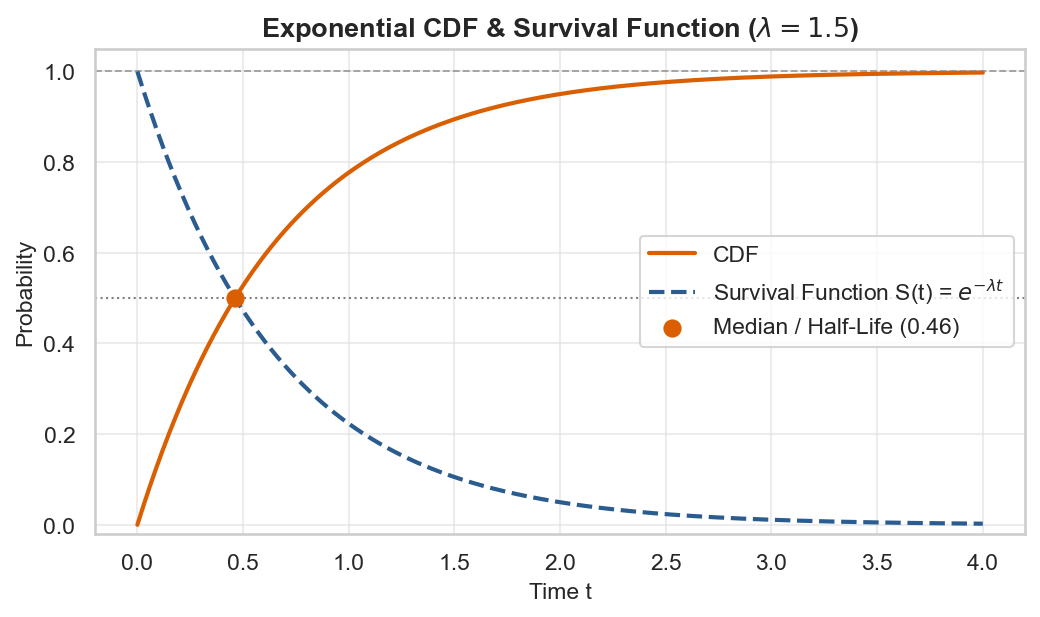

In [6]:
cdf_vals = stats.expon.cdf(t_axis, scale=scale)
survival_vals = stats.expon.sf(t_axis, scale=scale)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    t_axis,
    cdf_vals,
    is_discrete=False,
    title=rf"Exponential CDF & Survival Function ($\lambda = {lam}$)",
    xlabel="Time t",
    ylabel="Probability",
    ax=ax,
)
ax.plot(
    t_axis,
    survival_vals,
    color=PALETTE["primary"],
    linestyle="--",
    linewidth=2,
    label="Survival Function S(t) = $e^{-\lambda t}$",
)
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
median_val = np.log(2) / lam
ax.scatter([median_val], [0.5], color=PALETTE["secondary"], s=60, zorder=5, label=f"Median / Half-Life ({median_val:.2f})")
ax.legend(frameon=True)
plt.show()

## 3. Key Theoretical Properties

### 1. Moments (Equal Mean and Standard Deviation)
- **Mean**: $\mu = \frac{1}{\lambda}$
- **Variance**: $\sigma^2 = \frac{1}{\lambda^2}$
- **Standard Deviation**: $\sigma = \frac{1}{\lambda} = \mu$
*(In an Exponential distribution, the standard deviation is always **strictly equal to the mean**).*

### 2. Shape Characteristics
- **Skewness ($\gamma_1$)**: $2$ (constant positive skew, independent of $\lambda$).
- **Excess Kurtosis ($\gamma_2$)**: $6$ (constant heavy tail).
- **Median (Half-Life)**:
  $$x_{\text{med}} = \frac{\ln(2)}{\lambda} \approx 0.6931 \times \mu$$
  *(Because of positive skew, the median is always $\approx 30.7\%$ smaller than the mean).*

### 3. The Memoryless Property
The Exponential distribution is the **only continuous distribution** that is memoryless:
$$P(X > s + t \mid X > s) = P(X > t)$$
*Meaning:* If a component has survived $s$ hours without failure, the probability that it survives an additional $t$ hours is identical to a brand new component surviving $t$ hours. It experiences **no aging or wear-and-tear**.

In [8]:
# Verify moments against SciPy
lam_test = 2.5
scale_test = 1.0 / lam_test

mu_form = 1.0 / lam_test
var_form = 1.0 / (lam_test**2)
std_form = 1.0 / lam_test
skew_form = 2.0
kurt_form = 6.0

mu_sp, var_sp, skew_sp, kurt_sp = stats.expon.stats(
    scale=scale_test, moments="mvsk"
)

print("--- EXPONENTIAL THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical | SciPy")
print("-" * 46)
print(f"Mean (μ = 1/λ)       | {mu_form:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ² = 1/λ²) | {var_form:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_form:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_form:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_form:10.4f} | {float(kurt_sp):10.4f}")
print(f"\nRatio of Std Dev to Mean (σ / μ): {std_form / mu_form:.1f} (Always Exactly 1.0)")

--- EXPONENTIAL THEORETICAL MOMENTS ---
Moment               | Analytical | SciPy
----------------------------------------------
Mean (μ = 1/λ)       |     0.4000 |     0.4000
Variance (σ² = 1/λ²) |     0.1600 |     0.1600
Std Deviation (σ)    |     0.4000 |     0.4000
Skewness (γ₁)        |     2.0000 |     2.0000
Excess Kurtosis (γ₂) |     6.0000 |     6.0000

Ratio of Std Dev to Mean (σ / μ): 1.0 (Always Exactly 1.0)


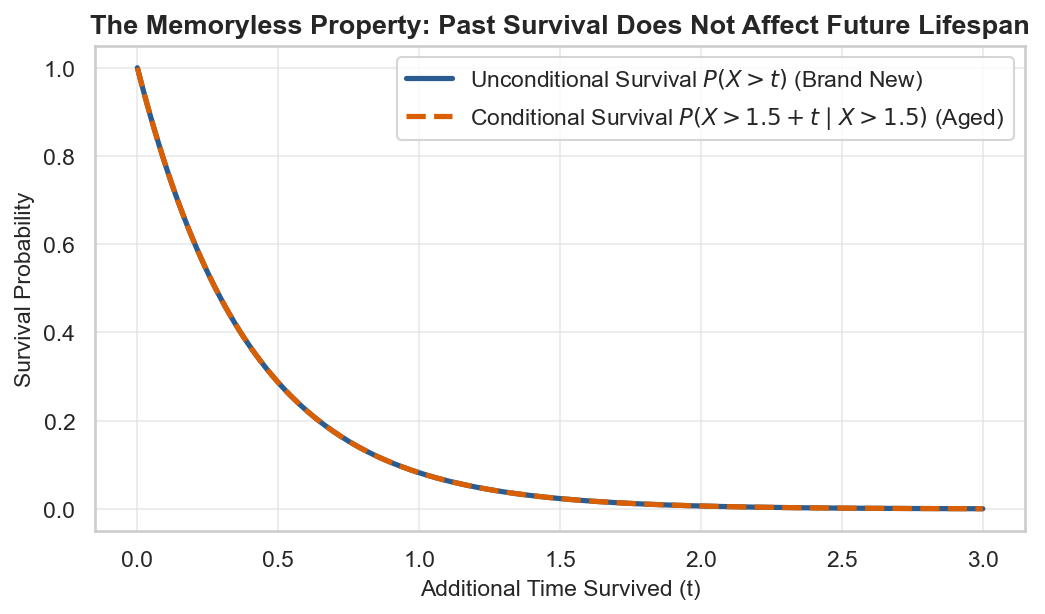

Max difference between conditional and unconditional: 6.66e-16


In [10]:
# Parameters for Memoryless demonstration
s = 1.5  # already survived 1.5 hours
t_span = np.linspace(0, 3, 200)

# Unconditional survival: P(X > t) = exp(-lambda * t)
p_uncond = stats.expon.sf(t_span, scale=scale_test)

# Conditional survival: P(X > s + t | X > s) = P(X > s + t) / P(X > s)
p_cond = stats.expon.sf(s + t_span, scale=scale_test) / stats.expon.sf(s, scale=scale_test)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(t_span, p_uncond, color=PALETTE["primary"], linewidth=2.5, label="Unconditional Survival $P(X > t)$ (Brand New)")
ax.plot(t_span, p_cond, color=PALETTE["secondary"], linestyle="--", linewidth=2.5, label=rf"Conditional Survival $P(X > {s} + t \mid X > {s})$ (Aged)")

ax.set_title("The Memoryless Property: Past Survival Does Not Affect Future Lifespan", weight="bold")
ax.set_xlabel("Additional Time Survived (t)")
ax.set_ylabel("Survival Probability")
ax.legend(frameon=True)
plt.show()

print(f"Max difference between conditional and unconditional: {np.max(np.abs(p_cond - p_uncond)):.2e}")

## 4. Parameter Variation

The single rate parameter $\lambda$ determines the speed of exponential decay:
- **High Rate ($\lambda = 3.0$ or $4.0$)**: Events occur frequently; waiting times are short ($\mu \le 0.33$), and the curve plummets rapidly.
- **Moderate Rate ($\lambda = 1.0$)**: Standard decay with $\mu = 1.0$.
- **Low Rate ($\lambda = 0.25$ or $0.5$)**: Events are rare; long waiting times ($\mu \ge 2.0$), creating a prolonged tail.

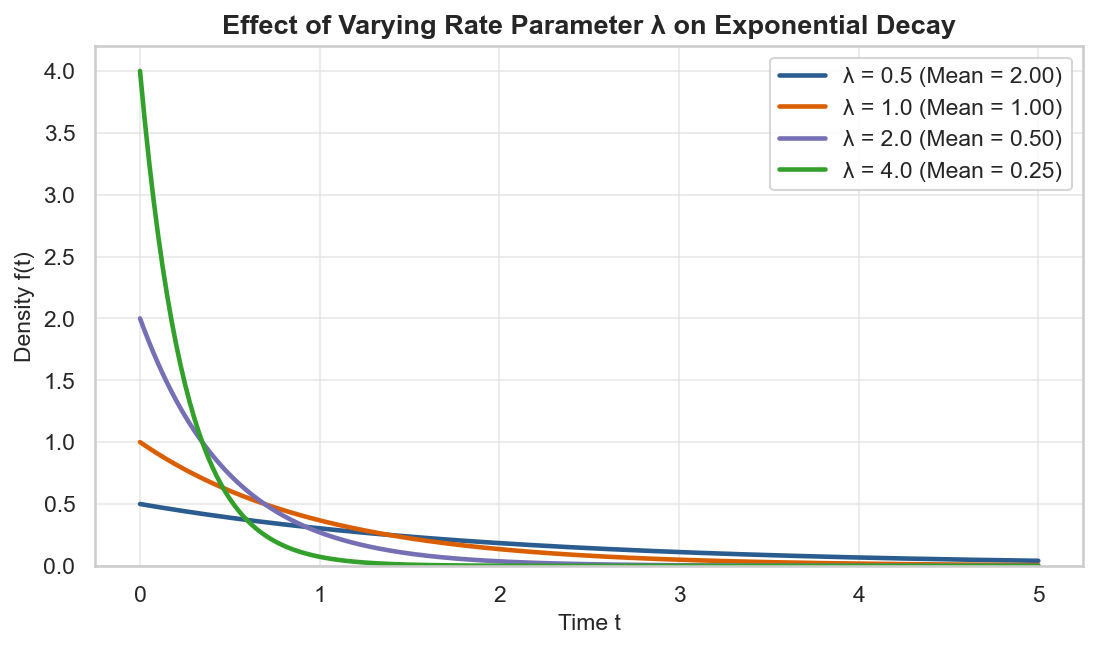

In [11]:
rates = [0.5, 1.0, 2.0, 4.0]
colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"], "#33a02c"]
t_eval_p = np.linspace(0, 5, 400)

fig, ax = plt.subplots(figsize=(8.5, 4.5))

for r_val, col in zip(rates, colors):
    pdf = stats.expon.pdf(t_eval_p, scale=1.0 / r_val)
    ax.plot(
        t_eval_p,
        pdf,
        color=col,
        linewidth=2.2,
        label=f"λ = {r_val:.1f} (Mean = {1/r_val:.2f})",
    )

ax.set_title("Effect of Varying Rate Parameter λ on Exponential Decay", weight="bold")
ax.set_xlabel("Time t")
ax.set_ylabel("Density f(t)")
ax.set_ylim(0, 4.2)
ax.legend(frameon=True)
plt.show()

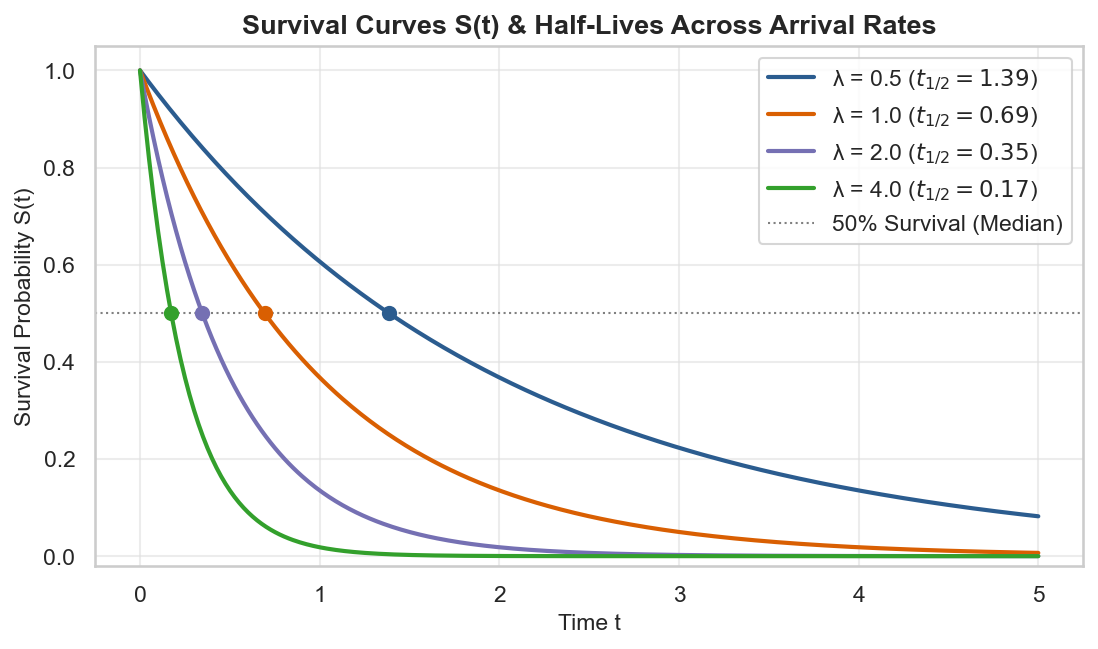

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

for r_val, col in zip(rates, colors):
    sf = stats.expon.sf(t_eval_p, scale=1.0 / r_val)
    t_half = np.log(2) / r_val
    ax.plot(t_eval_p, sf, color=col, linewidth=2.0, label=f"λ = {r_val:.1f} ($t_{{1/2}} = {t_half:.2f}$)")
    ax.scatter([t_half], [0.5], color=col, s=40, zorder=5)

ax.axhline(0.5, color="gray", linestyle=":", linewidth=1, label="50% Survival (Median)")
ax.set_title("Survival Curves S(t) & Half-Lives Across Arrival Rates", weight="bold")
ax.set_xlabel("Time t")
ax.set_ylabel("Survival Probability S(t)")
ax.set_ylim(-0.02, 1.05)
ax.legend(frameon=True)
plt.show()

## 5. Simulation & Law of Large Numbers

When we simulate $N$ independent draws $X_1, X_2, \dots, X_N \sim \text{Exponential}(\lambda)$:
1. By the **Law of Large Numbers**:
   $$\bar{X}_N = \frac{1}{N}\sum_{i=1}^N X_i \xrightarrow{P} \frac{1}{\lambda}$$
2. The sample standard deviation also converges to the exact same value: $s_N \to \frac{1}{\lambda}$.

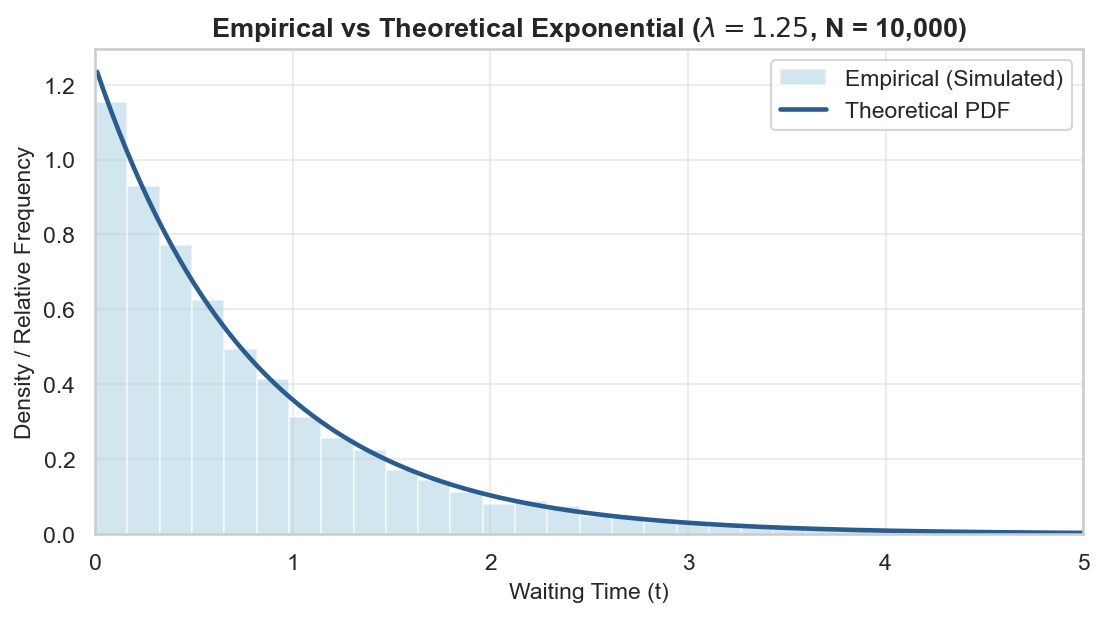

In [15]:
from utils.plotting import plot_sample_vs_theory

lam_sim = 1.25
scale_sim = 1.0 / lam_sim  # 0.80
sample_size = 10000

# Generate pseudo-random Exponential variates
samples_exp = stats.expon.rvs(scale=scale_sim, size=sample_size, random_state=42)

# Theoretical coordinates
t_th = np.linspace(0.01, 5.0, 400)
pdf_th = stats.expon.pdf(t_th, scale=scale_sim)

# Plot empirical histogram vs theoretical PDF
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_sample_vs_theory(
    samples=samples_exp,
    x_theory=t_th,
    y_theory=pdf_th,
    is_discrete=False,
    title=rf"Empirical vs Theoretical Exponential ($\lambda = {lam_sim}$, N = {sample_size:,})",
    xlabel="Waiting Time (t)",
    ax=ax,
)
ax.set_xlim(0, 5)
plt.show()

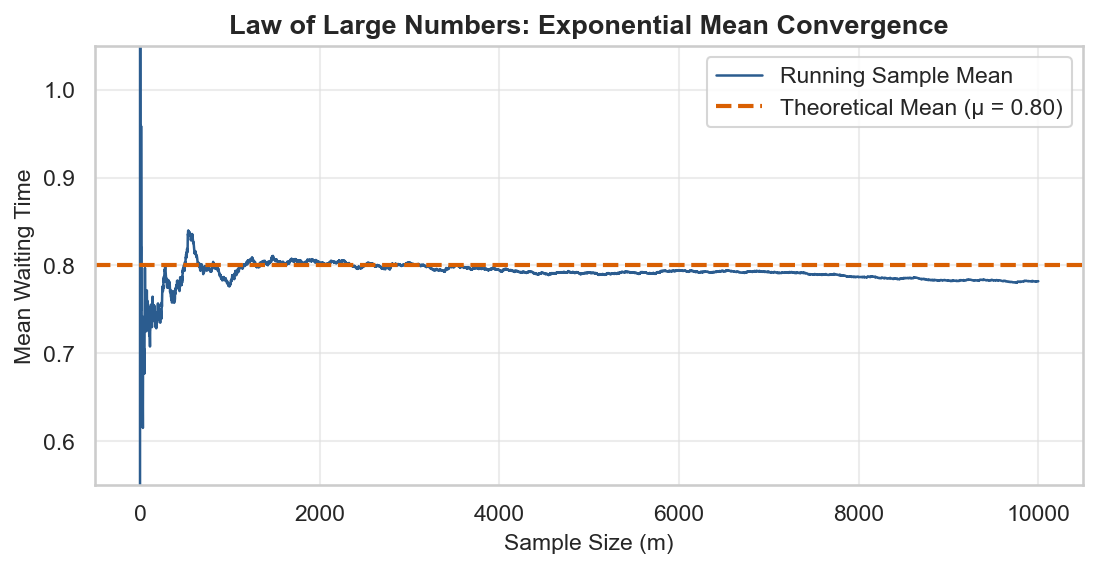

Sample Mean: 0.7820 (Theoretical: 0.8000)
Sample Std:  0.7795 (Theoretical: 0.8000)


In [16]:
# Running average convergence
running_exp_mean = np.cumsum(samples_exp) / np.arange(1, sample_size + 1)
plt.figure(figsize=(8.5, 3.8))
plt.plot(running_exp_mean, color=PALETTE["primary"], linewidth=1.2, label="Running Sample Mean")
plt.axhline(scale_sim, color=PALETTE["secondary"], linestyle="--", linewidth=2, label=f"Theoretical Mean (μ = {scale_sim:.2f})")
plt.title("Law of Large Numbers: Exponential Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Mean Waiting Time")
plt.ylim(scale_sim - 0.25, scale_sim + 0.25)
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean: {np.mean(samples_exp):.4f} (Theoretical: {scale_sim:.4f})")
print(f"Sample Std:  {np.std(samples_exp, ddof=1):.4f} (Theoretical: {scale_sim:.4f})")

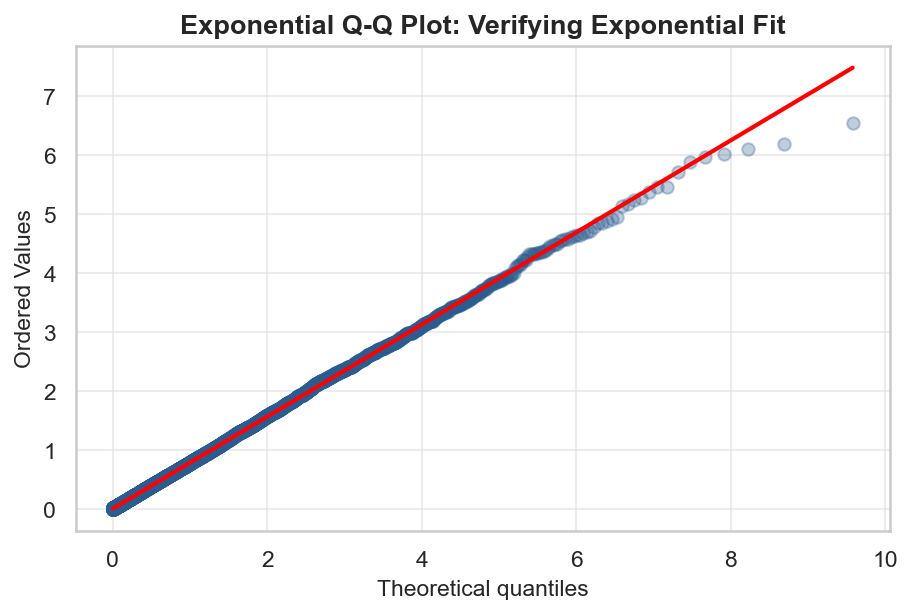

In [17]:
# Exponential Q-Q Plot Diagnostic
fig, ax = plt.subplots(figsize=(7, 4.2))
stats.probplot(samples_exp, dist="expon", plot=ax)

# Style Q-Q plot
ax.get_lines()[0].set_markerfacecolor(PALETTE["primary"])
ax.get_lines()[0].set_color(PALETTE["primary"])
ax.get_lines()[0].set_alpha(0.3)
ax.get_lines()[1].set_color("red")
ax.get_lines()[1].set_linewidth(2)

ax.set_title("Exponential Q-Q Plot: Verifying Exponential Fit", weight="bold")
plt.show()

## 6. Applied Real-World Use Case: Hardware Reliability & Mean Time Between Failures (MTBF)

### Scenario
A cloud infrastructure provider operates a fleet of solid-state drives (SSDs).
During the steady-state operating phase (after burn-in and before wear-out), electronic components experience a **constant failure rate**:
$$\lambda = 0.0002 \text{ failures per day}$$

### Reliability Metrics:
1. **Mean Time Between Failures (MTBF)**:
   $$\text{MTBF} = \mu = \frac{1}{\lambda} = \frac{1}{0.0002} = 5,000 \text{ days} \approx 13.7 \text{ years}$$
2. **Warranty Survival**: What percentage of drives survive past the 3-year warranty ($t = 1,095$ days)?
   $$S(1095) = e^{-\lambda \times 1095} = e^{-0.0002 \times 1095} \approx e^{-0.219} \approx 80.3\%$$
3. **Half-Life ($t_{1/2}$)**: Time until exactly 50% of original drives have failed:
   $$t_{1/2} = \frac{\ln(2)}{\lambda} \approx 3,465 \text{ days} \approx 9.5 \text{ years}$$

In [18]:
lam_ssd = 0.0002  # failures per day
mtbf_days = 1.0 / lam_ssd  # 5,000 days
warranty_days = 3 * 365  # 1,095 days

# Survival probability past warranty
prob_survive_warranty = stats.expon.sf(warranty_days, scale=mtbf_days)
prob_fail_warranty = 1.0 - prob_survive_warranty

# Median lifespan (half-life)
median_lifespan_days = np.log(2) / lam_ssd

# Annual Failure Rate (AFR): P(fail in 1 year = 365 days)
afr = stats.expon.cdf(365, scale=mtbf_days)

print("--- DATA CENTER SSD RELIABILITY REPORT ---")
print(f"Daily Failure Rate (λ):      {lam_ssd:.6f} / day")
print(f"MTBF:                        {mtbf_days:,.0f} days ({mtbf_days/365:.1f} years)\n")
print(f"3-Year Warranty Survival:    {prob_survive_warranty * 100:.2f}%")
print(f"3-Year Warranty Failure:     {prob_fail_warranty * 100:.2f}%")
print(f"Annualized Failure Rate:     {afr * 100:.2f}% per year")
print(f"Median Lifespan (Half-Life): {median_lifespan_days:,.0f} days ({median_lifespan_days/365:.1f} years)")

--- DATA CENTER SSD RELIABILITY REPORT ---
Daily Failure Rate (λ):      0.000200 / day
MTBF:                        5,000 days (13.7 years)

3-Year Warranty Survival:    80.33%
3-Year Warranty Failure:     19.67%
Annualized Failure Rate:     7.04% per year
Median Lifespan (Half-Life): 3,466 days (9.5 years)


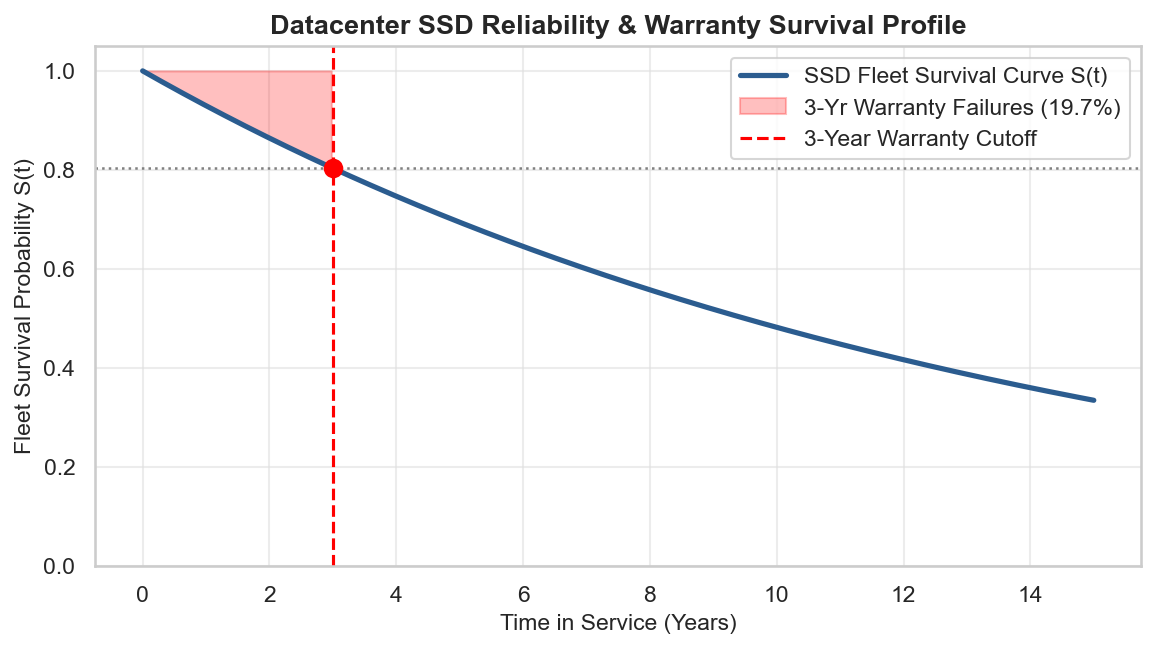

In [19]:
days_axis = np.linspace(0, 15 * 365, 500)
survival_curve = stats.expon.sf(days_axis, scale=mtbf_days)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(days_axis / 365, survival_curve, color=PALETTE["primary"], linewidth=2.5, label="SSD Fleet Survival Curve S(t)")

# Highlight Warranty Interval (First 3 years)
mask_warr = days_axis <= warranty_days
ax.fill_between(
    days_axis[mask_warr] / 365,
    survival_curve[mask_warr],
    1.0,
    color="red",
    alpha=0.25,
    label=f"3-Yr Warranty Failures ({prob_fail_warranty*100:.1f}%)",
)

ax.axvline(3.0, color="red", linestyle="--", linewidth=1.5, label="3-Year Warranty Cutoff")
ax.axhline(prob_survive_warranty, color="gray", linestyle=":", linewidth=1.2)
ax.scatter([3.0], [prob_survive_warranty], color="red", s=70, zorder=5)

ax.set_title("Datacenter SSD Reliability & Warranty Survival Profile", weight="bold")
ax.set_xlabel("Time in Service (Years)")
ax.set_ylabel("Fleet Survival Probability S(t)")
ax.set_ylim(0, 1.05)
ax.legend(frameon=True)
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given $N$ observed waiting times $x_1, x_2, \dots, x_N$:

### The Likelihood Function
$$L(\lambda) = \prod_{i=1}^{N} \lambda e^{-\lambda x_i} = \lambda^N \exp\left(-\lambda \sum_{i=1}^N x_i\right)$$

### Log-Likelihood & Optimization
$$\ln L(\lambda) = N \ln(\lambda) - \lambda \sum_{i=1}^{N} x_i$$

Differentiating with respect to $\lambda$ and setting to zero:
$$\frac{d}{d\lambda}\ln L(\lambda) = \frac{N}{\lambda} - \sum_{i=1}^{N} x_i = 0 \implies \hat{\lambda}_{\text{MLE}} = \frac{N}{\sum_{i=1}^N x_i} = \frac{1}{\bar{x}}$$

The Maximum Likelihood Estimate of the arrival rate is simply the **reciprocal of the sample mean waiting time**!

### Standard Error
By the Fisher Information, the asymptotic standard error is:
$$\text{SE}(\hat{\lambda}) = \frac{\hat{\lambda}}{\sqrt{N}}$$

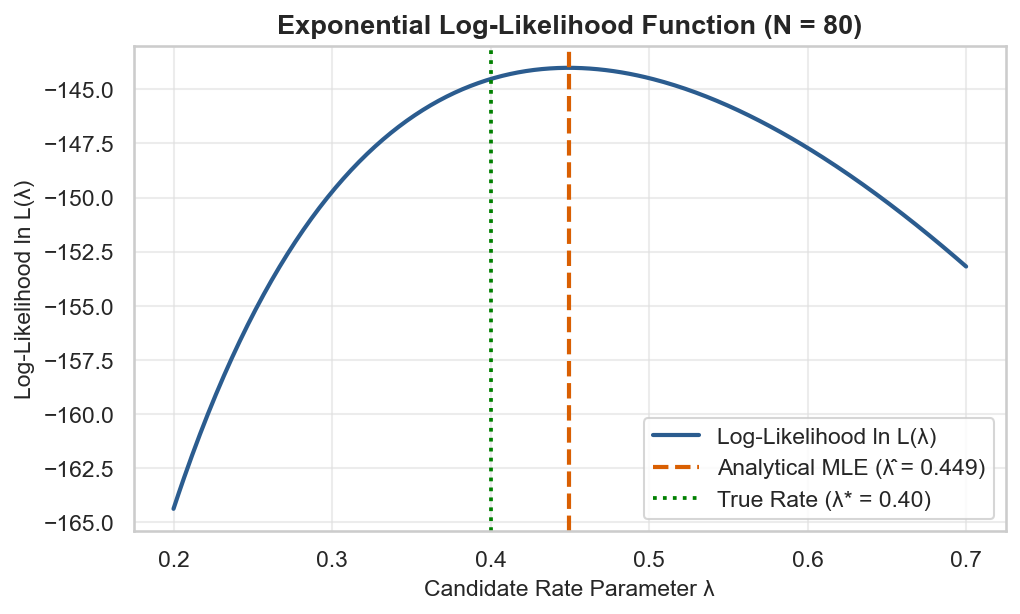

In [20]:
# True rate parameter
lam_true = 0.40
N_obs = 80

# Generate synthetic observations
data_exp = stats.expon.rvs(scale=1.0 / lam_true, size=N_obs, random_state=123)

# Analytical MLE: 1 / sample_mean
lam_mle = 1.0 / np.mean(data_exp)


# Log-likelihood function
def expon_log_lik(l_grid, data):
    n = len(data)
    sum_x = np.sum(data)
    return n * np.log(l_grid) - l_grid * sum_x


l_candidates = np.linspace(0.20, 0.70, 300)
log_lik_curve = expon_log_lik(l_candidates, data_exp)

plt.figure(figsize=(7.5, 4.2))
plt.plot(l_candidates, log_lik_curve, color=PALETTE["primary"], linewidth=2, label="Log-Likelihood ln L(λ)")
plt.axvline(lam_mle, color=PALETTE["secondary"], linestyle="--", linewidth=2, label=f"Analytical MLE (λ̂ = {lam_mle:.3f})")
plt.axvline(lam_true, color="green", linestyle=":", linewidth=1.8, label=f"True Rate (λ* = {lam_true:.2f})")

plt.title(f"Exponential Log-Likelihood Function (N = {N_obs})", weight="bold")
plt.xlabel("Candidate Rate Parameter λ")
plt.ylabel("Log-Likelihood ln L(λ)")
plt.legend(frameon=True)
plt.show()

In [21]:
from scipy.optimize import minimize


# Negative log-likelihood objective
def neg_log_lik_exp(l_param, data):
    l_val = np.clip(l_param[0], 1e-5, 1e3)
    return -np.sum(stats.expon.logpdf(data, scale=1.0 / l_val))


res = minimize(neg_log_lik_exp, x0=[1.0], args=(data_exp,), bounds=[(1e-4, 100.0)])
lam_mle_num = res.x[0]

# Standard Error & 95% Confidence Interval
se_lam = lam_mle_num / np.sqrt(N_obs)
ci_low = lam_mle_num - 1.96 * se_lam
ci_high = lam_mle_num + 1.96 * se_lam

print("--- EXPONENTIAL MLE ESTIMATION RESULTS ---")
print(f"Sample Size (N):            {N_obs}")
print(f"Sample Mean Waiting Time:   {np.mean(data_exp):.3f} time units\n")
print(f"True Rate (λ*):             {lam_true:.4f}")
print(f"Analytical MLE (1 / x̄):     {lam_mle:.4f}")
print(f"Numerical MLE (Optimizer):  {lam_mle_num:.4f}")
print(f"Standard Error (SE):        {se_lam:.4f}")
print(f"95% Confidence Interval:    [{ci_low:.4f}, {ci_high:.4f}]")

--- EXPONENTIAL MLE ESTIMATION RESULTS ---
Sample Size (N):            80
Sample Mean Waiting Time:   2.226 time units

True Rate (λ*):             0.4000
Analytical MLE (1 / x̄):     0.4493
Numerical MLE (Optimizer):  0.4493
Standard Error (SE):        0.0502
95% Confidence Interval:    [0.3508, 0.5477]


## 8. Related Distributions & Summary

The Exponential distribution sits at the crossroads of continuous stochastic processes:

1. **Poisson Process (Inter-Arrival Duality)**:
   - If arrivals follow a Poisson process with rate $\lambda$, the waiting time between consecutive arrivals follows $\text{Exponential}(\lambda)$.
2. **Gamma (Erlang) Distribution**:
   - The sum of $k$ independent $\text{Exponential}(\lambda)$ variables is a **Gamma distribution**:
     $$T_k = \sum_{i=1}^k X_i \sim \text{Gamma}(\text{shape}=k, \text{rate}=\lambda)$$
   - *(Gamma models the waiting time for $k$ Poisson events to occur).*
3. **Geometric Distribution (Discrete Analog)**:
   - The Geometric distribution is the discrete waiting time until the first success.
   - Exponential is its continuous limit; both are the **only memoryless distributions** in their domains.
4. **Weibull Distribution (Generalizing Aging)**:
   - The Exponential distribution assumes a constant hazard rate $h(t) = \lambda$.
   - The **Weibull distribution** introduces a shape parameter $k$ allowing hazard rates to increase with age ($k > 1$, wear-out) or decrease ($k < 1$, infant mortality).

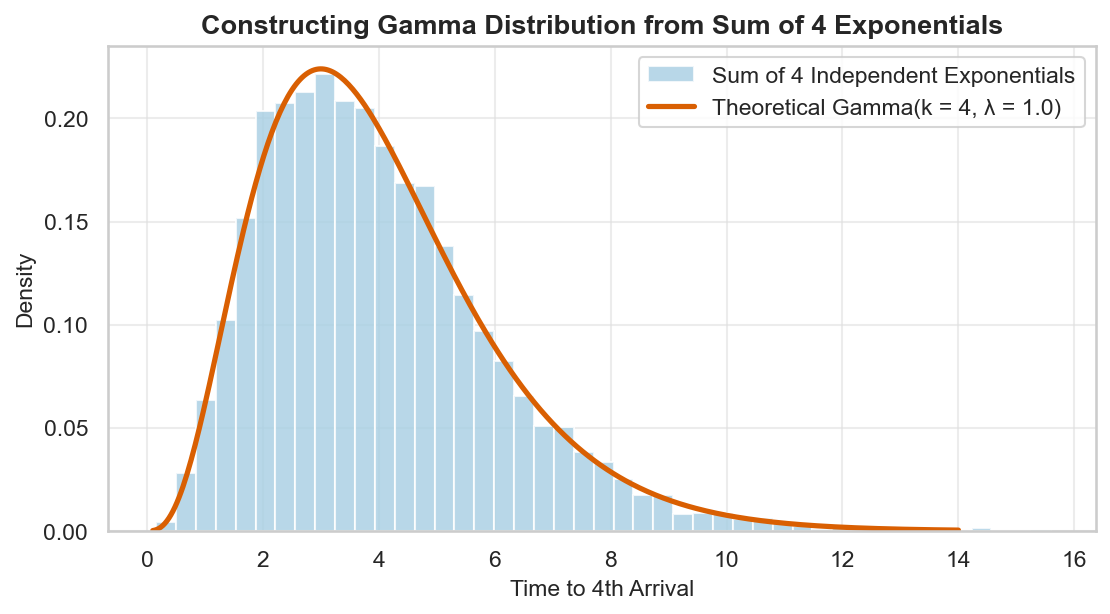

Mean of Sums: 3.987 (Theoretical k/λ = 4.0)
Var of Sums:  3.942 (Theoretical k/λ² = 4.0)


In [22]:
# Parameters: Summing k = 4 independent exponentials
k_events = 4
lam_val = 1.0
n_sim_gamma = 10000

# 1. Generate matrix of Exponential draws: Shape (10000, 4)
exp_matrix = stats.expon.rvs(scale=1.0 / lam_val, size=(n_sim_gamma, k_events), random_state=42)

# 2. Sum along columns: T_k = sum(X_i)
gamma_sums = np.sum(exp_matrix, axis=1)

# 3. Compare empirical sums against theoretical Gamma(shape = k, scale = 1/lambda)
t_gamma_eval = np.linspace(0.1, 14.0, 400)
pdf_gamma_true = stats.gamma.pdf(t_gamma_eval, a=k_events, scale=1.0 / lam_val)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(
    gamma_sums,
    bins=45,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label=f"Sum of {k_events} Independent Exponentials",
)
ax.plot(
    t_gamma_eval,
    pdf_gamma_true,
    color=PALETTE["secondary"],
    linewidth=2.5,
    label=f"Theoretical Gamma(k = {k_events}, λ = {lam_val})",
)

ax.set_title(f"Constructing Gamma Distribution from Sum of {k_events} Exponentials", weight="bold")
ax.set_xlabel("Time to 4th Arrival")
ax.set_ylabel("Density")
ax.legend(frameon=True)
plt.show()

print(f"Mean of Sums: {np.mean(gamma_sums):.3f} (Theoretical k/λ = {k_events / lam_val:.1f})")
print(f"Var of Sums:  {np.var(gamma_sums, ddof=1):.3f} (Theoretical k/λ² = {k_events / (lam_val**2):.1f})")

### Summary Card: Exponential Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \text{Exponential}(\lambda)$ |
| **Parameters** | $\lambda > 0$ (rate parameter), or $\beta = 1/\lambda$ (scale / mean) |
| **Support** | $x \in [0, \infty)$ |
| **PDF** | $f(x) = \lambda e^{-\lambda x}$ |
| **CDF** | $F(x) = 1 - e^{-\lambda x}$ |
| **Survival Function** | $S(x) = e^{-\lambda x}$ |
| **Hazard Function** | $h(x) = \lambda$ (Constant Failure Rate) |
| **Mean ($\mu$)** | $\frac{1}{\lambda}$ |
| **Variance ($\sigma^2$)** | $\frac{1}{\lambda^2}$ |
| **Standard Deviation ($\sigma$)** | $\frac{1}{\lambda} = \mu$ (Always equals mean) |
| **Skewness ($\gamma_1$)** | $2$ (Constant positive skew) |
| **Excess Kurtosis ($\gamma_2$)** | $6$ (Constant heavy tail) |
| **Median (Half-Life)** | $\frac{\ln(2)}{\lambda} \approx 0.6931 \times \mu$ |
| **Memoryless Property** | $P(X > s + t \mid X > s) = P(X > t)$ |
| **MLE Estimator** | $\hat{\lambda} = \frac{1}{\bar{x}}$ |
| **Key Use Cases** | Hardware MTBF, customer service queues, survival analysis, radioactive decay |